<a href="https://colab.research.google.com/github/yudetamagochan/personal_planner/blob/main/personal_planner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import random
from collections import deque
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# マップサイズ
MAP_H = 30
MAP_W = 30

# 8方向移動
DIRECTIONS = [
    (-1, -1),  # 左上
    (0, -1),   # 上
    (1, -1),   # 右上
    (-1, 0),   # 左
    (1, 0),    # 右
    (-1, 1),   # 左下
    (0, 1),    # 下
    (1, 1),    # 右下
]

DIRECTION_NAMES = [
    "左上", "上", "右上",
    "左", "右",
    "左下", "下", "右下"
]

# 斜め移動のコスト
MOVE_COSTS = [
    math.sqrt(2), 1.0, math.sqrt(2),
    1.0, 1.0,
    math.sqrt(2), 1.0, math.sqrt(2)
]

# 人の移動速度
SPEED_VALUES = {
    "low": 0.25,
    "high": 0.8,
}

# 属性別の回避半径への追加値
MOBILITY_EXTRA = {
    "normal": 0.0,
    "vulnerable": 2.0,   # 車いす・松葉杖など
}

SPEED_EXTRA = {
    "low": 0.0,
    "high": 0.8,
}

COOPERATION_EXTRA = {
    True: 0.0,           # 協調的な人は小さく避ける
    False: 1.5,          # 非協調的な人は大きく避ける
}

BASE_RADIUS = 1.8

In [3]:
def make_human(
    position,
    direction=(1, 0),
    speed_class="low",
    mobility="normal",
    cooperative=True
):
    """
    人を作成する。

    position:
        (x, y)
    direction:
        移動方向。例：(1, 0)なら右方向
    speed_class:
        "low" または "high"
    mobility:
        "normal" または "vulnerable"
    cooperative:
        Trueなら協調的、Falseなら非協調的
    """
    dx, dy = direction
    norm = math.sqrt(dx**2 + dy**2)

    if norm == 0:
        dx, dy = 0.0, 0.0
    else:
        dx, dy = dx / norm, dy / norm

    return {
        "position": tuple(position),
        "direction": (dx, dy),
        "speed_class": speed_class,
        "mobility": mobility,
        "cooperative": cooperative,
    }


def avoidance_radius(human):
    """
    人の属性からロボットの回避半径を計算する。
    """
    radius = BASE_RADIUS

    radius += MOBILITY_EXTRA[human["mobility"]]
    radius += SPEED_EXTRA[human["speed_class"]]
    radius += COOPERATION_EXTRA[human["cooperative"]]

    return radius


def human_speed(human):
    return SPEED_VALUES[human["speed_class"]]


def human_description(human):
    mobility_text = (
        "移動弱者"
        if human["mobility"] == "vulnerable"
        else "通常"
    )

    speed_text = (
        "低速"
        if human["speed_class"] == "low"
        else "高速"
    )

    cooperation_text = (
        "協調的"
        if human["cooperative"]
        else "非協調的"
    )

    return f"{mobility_text}・{speed_text}・{cooperation_text}"

In [4]:
def create_map():
    """
    障害物付きの2次元マップを作る。
    0: 通行可能
    1: 障害物
    """
    grid = np.zeros((MAP_H, MAP_W), dtype=np.int32)

    # 外周を障害物にする
    grid[0, :] = 1
    grid[-1, :] = 1
    grid[:, 0] = 1
    grid[:, -1] = 1

    # 縦の壁
    grid[5:22, 14] = 1

    # 壁に通路を作る
    grid[12:15, 14] = 0

    # 横の壁
    grid[20, 4:14] = 1

    return grid


grid = create_map()

start = (3, 25)
goal = (26, 4)

# 移動する人
human = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="low",
    mobility="normal",
    cooperative=True
)

print("人の条件：", human_description(human))
print("回避半径：", avoidance_radius(human))

人の条件： 通常・低速・協調的
回避半径： 1.8


In [5]:
def update_human(human, grid, dt=1.0):
    """
    人を一定速度で移動させる。
    マップ端に近づいたら移動方向を反転する。
    """
    x, y = human["position"]
    dx, dy = human["direction"]

    speed = human_speed(human)

    new_x = x + dx * speed * dt
    new_y = y + dy * speed * dt

    # 壁やマップ端に近づいた場合は反転
    if (
        new_x < 1.5 or
        new_x > MAP_W - 2.5 or
        new_y < 1.5 or
        new_y > MAP_H - 2.5
    ):
        dx, dy = -dx, -dy
        human["direction"] = (dx, dy)

        new_x = x + dx * speed * dt
        new_y = y + dy * speed * dt

    # 障害物に入らないようにする
    ix = int(round(new_x))
    iy = int(round(new_y))

    if (
        ix < 0 or ix >= MAP_W or
        iy < 0 or iy >= MAP_H or
        grid[iy, ix] == 1
    ):
        dx, dy = -dx, -dy
        human["direction"] = (dx, dy)

        new_x = x + dx * speed * dt
        new_y = y + dy * speed * dt

    human["position"] = (new_x, new_y)

In [6]:
def distance_to_human(cell, human):
    """
    マップ上のセルと人との距離を返す。
    """
    x, y = cell
    hx, hy = human["position"]

    return math.sqrt((x - hx)**2 + (y - hy)**2)


def person_cost(cell, human):
    """
    人との距離に応じたコスト。
    """
    distance = distance_to_human(cell, human)
    radius = avoidance_radius(human)

    # 回避半径内にはほぼ入れない
    if distance < radius:
        return 1000.0

    # 回避半径の近く
    elif distance < radius + 1.0:
        return 30.0

    # 少し近い
    elif distance < radius + 3.0:
        return 8.0

    # 遠い
    else:
        return 0.0


def human_future_cost(cell, human, prediction_steps=3):
    """
    人が進む方向側に少し追加コストを与える。
    高速な人の場合に、進行方向を少し大きく避けるための処理。
    """
    x, y = cell
    hx, hy = human["position"]
    dx, dy = human["direction"]

    speed = human_speed(human)

    future_x = hx + dx * speed * prediction_steps
    future_y = hy + dy * speed * prediction_steps

    future_distance = math.sqrt(
        (x - future_x)**2 + (y - future_y)**2
    )

    radius = avoidance_radius(human)

    if future_distance < radius:
        return 40.0
    elif future_distance < radius + 2.0:
        return 10.0
    else:
        return 0.0


def cell_cost(cell, grid, human):
    """
    A*で利用するセルの総コスト。
    """
    x, y = cell

    if x < 0 or x >= MAP_W or y < 0 or y >= MAP_H:
        return 10000.0

    if grid[y, x] == 1:
        return 10000.0

    return (
        1.0
        + person_cost(cell, human)
        + human_future_cost(cell, human)
    )

In [7]:
def heuristic(a, b):
    """
    A*のヒューリスティック関数。
    """
    return math.sqrt(
        (a[0] - b[0])**2 +
        (a[1] - b[1])**2
    )


def get_neighbors(position):
    """
    現在位置から移動できる候補を返す。
    """
    x, y = position

    for index, ((dx, dy), move_cost) in enumerate(
        zip(DIRECTIONS, MOVE_COSTS)
    ):
        nx = x + dx
        ny = y + dy

        if 0 <= nx < MAP_W and 0 <= ny < MAP_H:
            yield (nx, ny), index, move_cost


def astar(start, goal, grid, human):
    """
    人の回避コストを考慮したA*。
    """
    open_list = []
    open_list.append((0.0, start))

    came_from = {}
    cost_so_far = {start: 0.0}

    while open_list:
        # 最も評価値が小さいノードを選ぶ
        open_list.sort(key=lambda x: x[0])
        _, current = open_list.pop(0)

        if current == goal:
            break

        for next_position, direction_index, move_cost in get_neighbors(current):
            next_cell_cost = cell_cost(next_position, grid, human)

            if next_cell_cost >= 10000:
                continue

            new_cost = (
                cost_so_far[current]
                + move_cost
                + next_cell_cost
            )

            if (
                next_position not in cost_so_far
                or new_cost < cost_so_far[next_position]
            ):
                cost_so_far[next_position] = new_cost

                priority = (
                    new_cost
                    + heuristic(next_position, goal)
                )

                open_list.append((priority, next_position))

                came_from[next_position] = (
                    current,
                    direction_index
                )

    # 経路が見つからない場合
    if goal not in came_from:
        return [], []

    # 経路を復元
    path = []
    directions = []

    current = goal

    while current != start:
        path.append(current)

        previous, direction_index = came_from[current]
        directions.append(direction_index)

        current = previous

    path.append(start)

    path.reverse()
    directions.reverse()

    return path, directions

In [8]:
path, directions = astar(
    start=start,
    goal=goal,
    grid=grid,
    human=human
)

print("経路長：", len(path))

if len(path) == 0:
    print("経路が見つかりませんでした")
else:
    print("最初の移動方向：", DIRECTION_NAMES[directions[0]])

経路長： 30
最初の移動方向： 右上


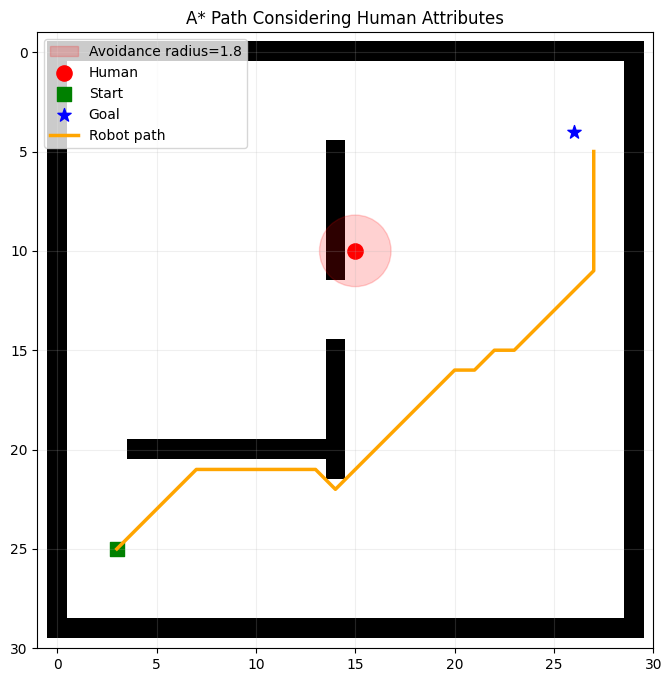

Input dimension: 17


In [41]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# 存在しないフォントによる警告を回避するため、標準の sans-serif を強制的に設定します
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']
mpl.rcParams['axes.unicode_minus'] = False

def plot_scene(
    grid,
    human,
    start=None,
    goal=None,
    robot_path=None,
    title=""
):
    plt.figure(figsize=(8, 8))

    # Display obstacles
    plt.imshow(
        grid,
        cmap="gray_r",
        origin="upper",
        vmin=0,
        vmax=1
    )

    # Human avoidance radius
    hx, hy = human["position"]
    radius = avoidance_radius(human)

    circle = plt.Circle(
        (hx, hy),
        radius,
        color="red",
        alpha=0.18,
        label=f"Avoidance radius={radius:.1f}"
    )

    plt.gca().add_patch(circle)

    # Human
    plt.scatter(
        [hx],
        [hy],
        c="red",
        s=120,
        marker="o",
        label="Human"
    )

    # Start
    if start is not None:
        plt.scatter(
            [start[0]],
            [start[1]],
            c="green",
            s=100,
            marker="s",
            label="Start"
        )

    # Goal
    if goal is not None:
        plt.scatter(
            [goal[0]],
            [goal[1]],
            c="blue",
            s=100,
            marker="*",
            label="Goal"
        )

    # Robot path
    if robot_path is not None and len(robot_path) > 0:
        xs = [p[0] for p in robot_path]
        ys = [p[1] for p in robot_path]

        plt.plot(
            xs,
            ys,
            color="orange",
            linewidth=2.5,
            label="Robot path"
        )

    plt.xlim(-1, MAP_W)
    plt.ylim(MAP_H, -1)
    plt.grid(alpha=0.2)
    plt.legend()
    plt.title(title)
    plt.show()


# Plot the scene
plot_scene(
    grid=grid,
    human=human,
    start=start,
    goal=goal,
    robot_path=path,
    title="A* Path Considering Human Attributes"
)


def local_obstacle_features(robot_position, grid):
    """
    Check whether obstacles exist in the 8 surrounding directions.
    """
    x, y = robot_position
    features = []

    for dx, dy in DIRECTIONS:
        nx = x + dx
        ny = y + dy

        if (
            nx < 0 or nx >= MAP_W or
            ny < 0 or ny >= MAP_H
        ):
            features.append(1.0)
        else:
            features.append(
                float(grid[ny, nx] == 1)
            )

    return features


def make_feature(robot_position, goal, human, grid):
    """
    Create input features for the MLP.
    """
    rx, ry = robot_position
    gx, gy = goal

    hx, hy = human["position"]
    dx, dy = human["direction"]

    speed = human_speed(human)

    mobility_flag = (
        1.0
        if human["mobility"] == "vulnerable"
        else 0.0
    )

    cooperation_flag = (
        1.0
        if human["cooperative"]
        else 0.0
    )

    feature = [
        (hx - rx) / MAP_W,
        (hy - ry) / MAP_H,
        dx,
        dy,
        speed,
        mobility_flag,
        cooperation_flag,
        (gx - rx) / MAP_W,
        (gy - ry) / MAP_H,
    ]

    feature += local_obstacle_features(
        robot_position,
        grid
    )

    return np.array(
        feature,
        dtype=np.float32
    )


# Check the input feature dimension
dummy_feature = make_feature(
    robot_position=start,
    goal=goal,
    human=human,
    grid=grid
)

INPUT_DIM = len(dummy_feature)

print("Input dimension:", INPUT_DIM)

In [61]:
def random_human():
    """
    ランダムな人を作成する。
    """
    position = (
        random.randint(4, MAP_W - 5),
        random.randint(4, MAP_H - 5)
    )

    directions = [
        (1, 0),
        (-1, 0),
        (0, 1),
        (0, -1)
    ]

    direction = random.choice(directions)

    speed_class = random.choice(["low", "high"])
    mobility = random.choice(["normal", "vulnerable"])

    # 移動弱者は今回は低速に限定
    if mobility == "vulnerable":
        speed_class = "low"

    cooperative = random.choice([True, False])

    return make_human(
        position=position,
        direction=direction,
        speed_class=speed_class,
        mobility=mobility,
        cooperative=cooperative
    )


def valid_position(position, grid):
    x, y = position

    return (
        0 <= x < MAP_W
        and 0 <= y < MAP_H
        and grid[y, x] == 0
    )


def generate_dataset(num_scenarios=500):
    """
    ランダムな環境を作り、A*の経路から教師データを作る。
    """
    X = []
    y = []

    for scenario_index in range(num_scenarios):
        local_grid = create_map()

        # 何度か試して有効なスタート・ゴールを作る
        for _ in range(100):
            local_start = (
                random.randint(2, MAP_W - 3),
                random.randint(2, MAP_H - 3)
            )

            local_goal = (
                random.randint(2, MAP_W - 3),
                random.randint(2, MAP_H - 3)
            )

            local_human = random_human()

            hx, hy = local_human["position"]

            # 人が障害物上にいないか
            if not valid_position((hx, hy), local_grid):
                continue

            # スタート・ゴールが障害物上にいないか
            if not valid_position(local_start, local_grid):
                continue

            if not valid_position(local_goal, local_grid):
                continue

            # スタート・ゴールが近すぎる場合を避ける
            if heuristic(local_start, local_goal) < 10:
                continue

            # スタートが人の回避半径内ならやり直す
            if (
                distance_to_human(local_start, local_human)
                < avoidance_radius(local_human) + 1
            ):
                continue

            break
        else:
            continue

        local_path, local_directions = astar(
            start=local_start,
            goal=local_goal,
            grid=local_grid,
            human=local_human
        )

        if len(local_path) < 2:
            continue

        # 経路上の状態を学習データにする
        for position, direction_index in zip(
            local_path[:-1],
            local_directions
        ):
            feature = make_feature(
                robot_position=position,
                goal=local_goal,
                human=local_human,
                grid=local_grid
            )

            X.append(feature)
            y.append(direction_index)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


X, y = generate_dataset(num_scenarios=700)

print("データ数：", len(X))
print("入力形状：", X.shape)
print("正解ラベル形状：", y.shape)

データ数： 12643
入力形状： (12643, 17)
正解ラベル形状： (12643,)


In [60]:
unique, counts = np.unique(y, return_counts=True)

for direction_index, count in zip(unique, counts):
    print(
        f"{direction_index}: "
        f"{DIRECTION_NAMES[direction_index]} "
        f"{count}件"
    )

0: 左上 1179件
1: 上 1828件
2: 右上 1293件
3: 左 1803件
4: 右 1944件
5: 左下 1382件
6: 下 1746件
7: 右下 1281件


In [44]:
class DirectionModel(nn.Module):
    def __init__(self, input_dim, output_dim=8):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.network(x)


model = DirectionModel(INPUT_DIM)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

DirectionModel(
  (network): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=8, bias=True)
  )
)


In [45]:
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

dataset = TensorDataset(X_tensor, y_tensor)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True
)

loss_history = []

EPOCHS = 30

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0.0
    total_count = 0
    correct_count = 0

    for batch_x, batch_y in loader:
        optimizer.zero_grad()

        logits = model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_x)

        predictions = torch.argmax(logits, dim=1)
        correct_count += (predictions == batch_y).sum().item()
        total_count += len(batch_x)

    average_loss = total_loss / total_count
    accuracy = correct_count / total_count

    loss_history.append(average_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:2d} / {EPOCHS}, "
            f"Loss: {average_loss:.4f}, "
            f"Accuracy: {accuracy:.3f}"
        )

Epoch  5 / 30, Loss: 1.1267, Accuracy: 0.585
Epoch 10 / 30, Loss: 1.0303, Accuracy: 0.617
Epoch 15 / 30, Loss: 0.9667, Accuracy: 0.635
Epoch 20 / 30, Loss: 0.9206, Accuracy: 0.652
Epoch 25 / 30, Loss: 0.8901, Accuracy: 0.661
Epoch 30 / 30, Loss: 0.8651, Accuracy: 0.665


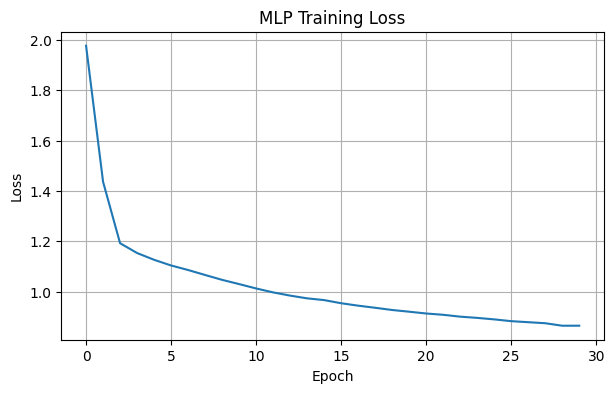

In [46]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# フォント警告回避のための設定
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss")
plt.grid()
plt.show()

In [58]:
def is_safe_position(position, grid, human):
    """
    次の位置が安全か判定する。
    """
    x, y = position

    if not valid_position(position, grid):
        return False

    distance = distance_to_human(position, human)

    if distance < avoidance_radius(human):
        return False

    return True


def safe_directions(robot_position, grid, human):
    """
    安全な移動方向のリストを返す。
    """
    safe = []

    x, y = robot_position

    for direction_index, (dx, dy) in enumerate(DIRECTIONS):
        next_position = (x + dx, y + dy)

        if is_safe_position(
            next_position,
            grid,
            human
        ):
            safe.append(direction_index)

    return safe

In [48]:
def model_predict_direction(
    robot_position,
    goal,
    human,
    grid,
    model
):
    """
    MLPで方向を予測する。
    """
    feature = make_feature(
        robot_position=robot_position,
        goal=goal,
        human=human,
        grid=grid
    )

    feature_tensor = torch.tensor(
        feature,
        dtype=torch.float32
    ).unsqueeze(0)

    model.eval()

    with torch.no_grad():
        logits = model(feature_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]

    # 確率の高い順に並べる
    ranked_directions = torch.argsort(
        probabilities,
        descending=True
    ).tolist()

    safe = safe_directions(
        robot_position,
        grid,
        human
    )

    # 安全な方向の中から、モデル確率が最も高いものを選ぶ
    for direction_index in ranked_directions:
        if direction_index in safe:
            return direction_index

    # 安全な方向がない場合
    return None


def generate_model_path(
    start,
    goal,
    grid,
    human,
    model,
    max_steps=150,
    human_dt=1.0
):
    """
    MLP + 安全フィルタで経路を作る。
    """
    robot_position = start
    robot_path = [robot_position]

    human_history = [human["position"]]

    min_human_distance = float("inf")
    reached_goal = False

    for step in range(max_steps):
        # 人を移動
        update_human(
            human,
            grid,
            dt=human_dt
        )

        human_history.append(human["position"])

        # 人との最小距離を記録
        current_distance = distance_to_human(
            robot_position,
            human
        )

        min_human_distance = min(
            min_human_distance,
            current_distance
        )

        # ゴールに到達したか
        if heuristic(robot_position, goal) <= 1.5:
            reached_goal = True
            break

        direction_index = model_predict_direction(
            robot_position=robot_position,
            goal=goal,
            human=human,
            grid=grid,
            model=model
        )

        if direction_index is None:
            break

        dx, dy = DIRECTIONS[direction_index]

        next_position = (
            robot_position[0] + dx,
            robot_position[1] + dy
        )

        if not is_safe_position(
            next_position,
            grid,
            human
        ):
            break

        robot_position = next_position
        robot_path.append(robot_position)

    return {
        "robot_path": robot_path,
        "human_history": human_history,
        "reached_goal": reached_goal,
        "min_human_distance": min_human_distance,
    }

Robot path length: 29
Reached goal: True
Minimum distance to human: 3.0


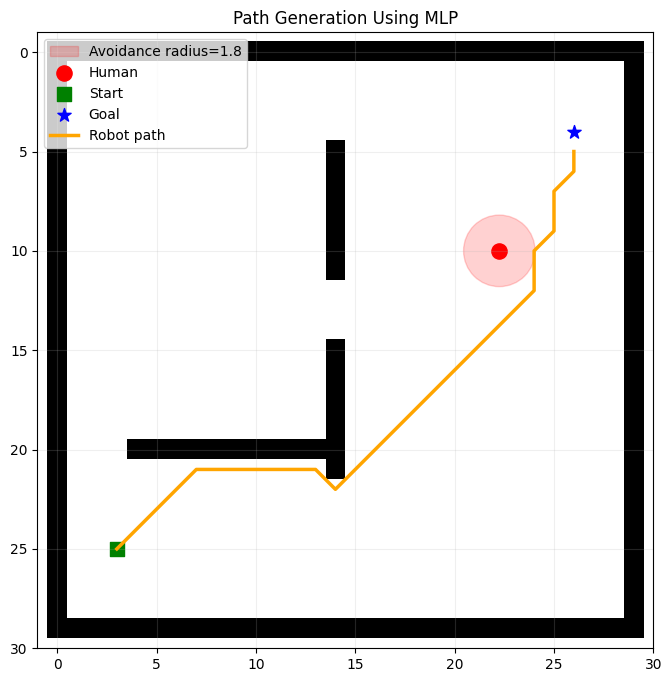

In [49]:
test_human = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="low",
    mobility="normal",
    cooperative=True
)

result = generate_model_path(
    start=start,
    goal=goal,
    grid=grid,
    human=test_human,
    model=model,
    max_steps=150
)

print("Robot path length:", len(result["robot_path"]))
print("Reached goal:", result["reached_goal"])
print(
    "Minimum distance to human:",
    round(result["min_human_distance"], 2)
)

plot_scene(
    grid=grid,
    human=test_human,
    start=start,
    goal=goal,
    robot_path=result["robot_path"],
    title="Path Generation Using MLP"
)

In [57]:
human_normal_cooperative = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="low",
    mobility="normal",
    cooperative=True
)

print(
    human_description(human_normal_cooperative),
    avoidance_radius(human_normal_cooperative)
)
human_fast = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="high",
    mobility="normal",
    cooperative=True
)

print(
    human_description(human_fast),
    avoidance_radius(human_fast)
)
human_vulnerable = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="low",
    mobility="vulnerable",
    cooperative=True
)

print(
    human_description(human_vulnerable),
    avoidance_radius(human_vulnerable)
)
human_vulnerable_noncoop = make_human(
    position=(15, 10),
    direction=(1, 0),
    speed_class="low",
    mobility="vulnerable",
    cooperative=False
)

print(
    human_description(human_vulnerable_noncoop),
    avoidance_radius(human_vulnerable_noncoop)
)


通常・低速・協調的 1.8
通常・高速・協調的 2.6
移動弱者・低速・協調的 3.8
移動弱者・低速・非協調的 5.3


In [56]:
conditions = {
    "Normal / Low Speed / Cooperative": make_human(
        position=(15, 10),
        direction=(1, 0),
        speed_class="low",
        mobility="normal",
        cooperative=True
    ),

    "Normal / High Speed / Cooperative": make_human(
        position=(15, 10),
        direction=(1, 0),
        speed_class="high",
        mobility="normal",
        cooperative=True
    ),

    "Vulnerable / Low Speed / Cooperative": make_human(
        position=(15, 10),
        direction=(1, 0),
        speed_class="low",
        mobility="vulnerable",
        cooperative=True
    ),

    "Vulnerable / Low Speed / Non-cooperative": make_human(
        position=(15, 10),
        direction=(1, 0),
        speed_class="low",
        mobility="vulnerable",
        cooperative=False
    ),
}


results = {}

for name, condition_human in conditions.items():
    result = generate_model_path(
        start=start,
        goal=goal,
        grid=grid,
        human=deepcopy(condition_human),
        model=model,
        max_steps=150
    )

    results[name] = result

    print(
        f"{name}: "
        f"Reached goal={result['reached_goal']}, "
        f"Path length={len(result['robot_path'])}, "
        f"Minimum distance={result['min_human_distance']:.2f}, "
        f"Avoidance radius={avoidance_radius(condition_human):.2f}"
    )

Normal / Low Speed / Cooperative: Reached goal=True, Path length=29, Minimum distance=3.00, Avoidance radius=1.80
Normal / High Speed / Cooperative: Reached goal=True, Path length=30, Minimum distance=3.01, Avoidance radius=2.60
Vulnerable / Low Speed / Cooperative: Reached goal=True, Path length=33, Minimum distance=6.01, Avoidance radius=3.80
Vulnerable / Low Speed / Non-cooperative: Reached goal=True, Path length=33, Minimum distance=6.01, Avoidance radius=5.30


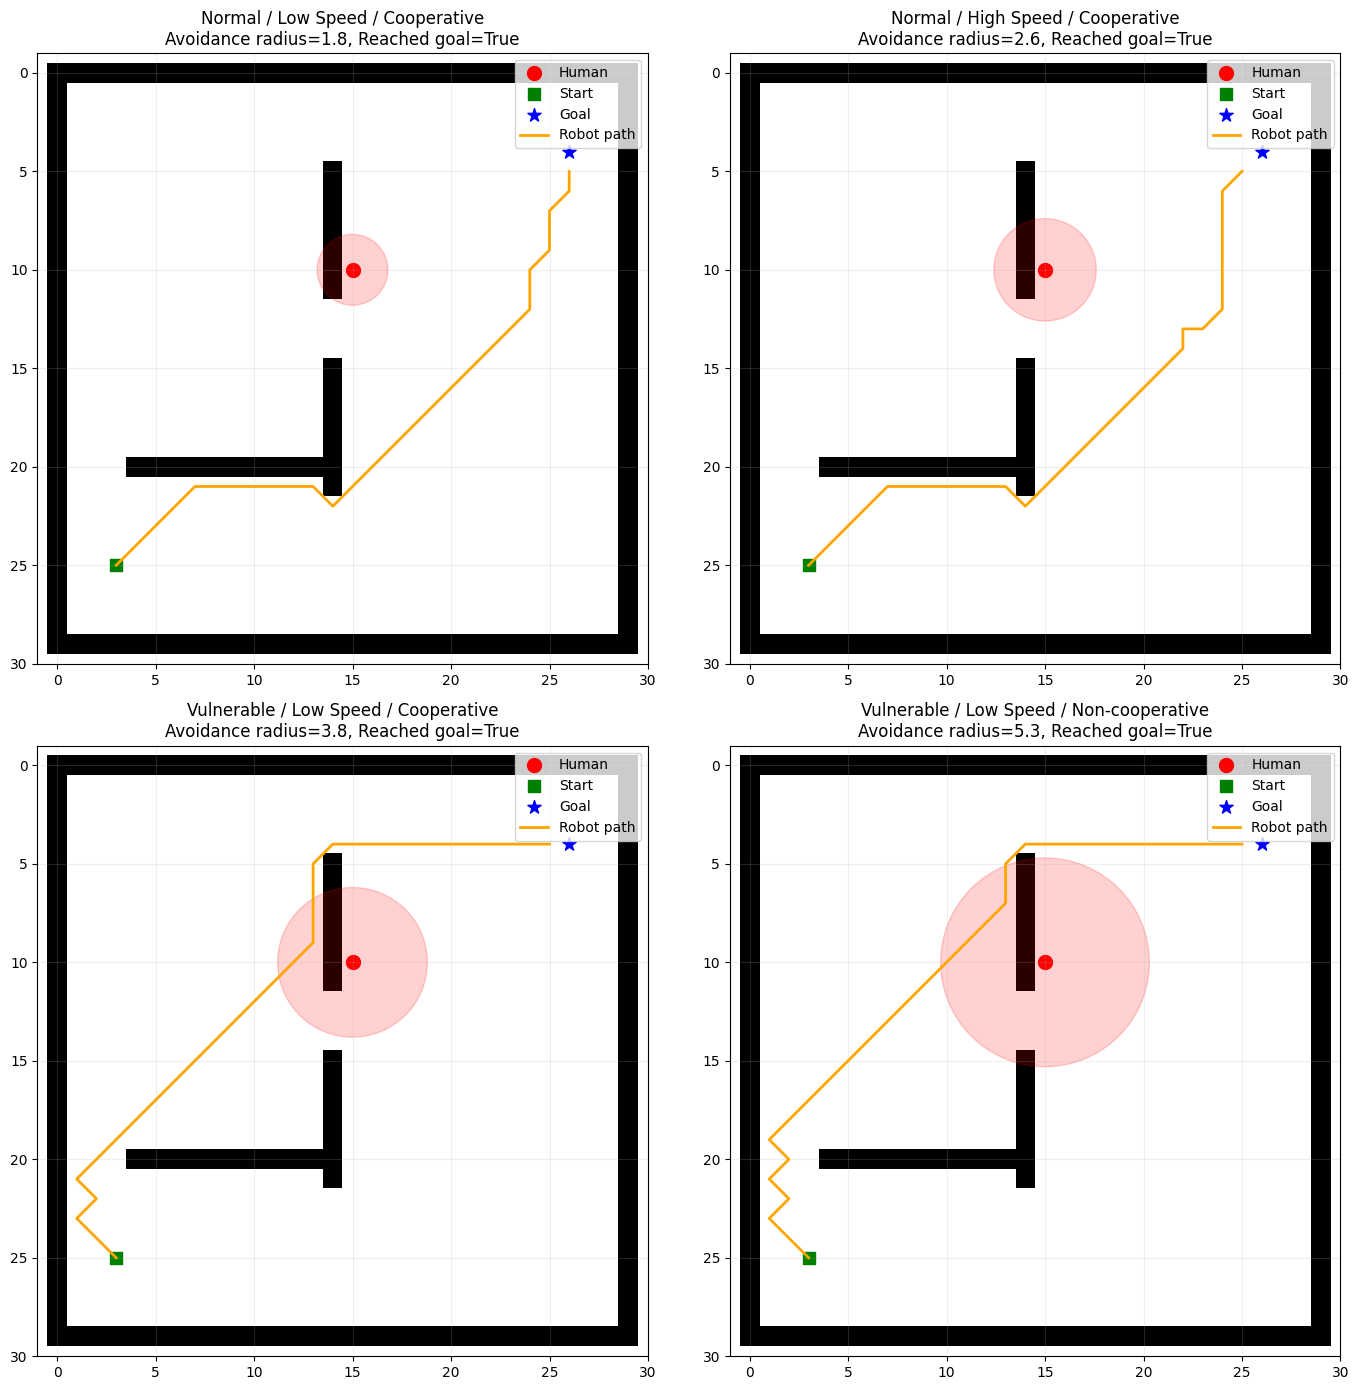

In [55]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# フォント警告回避のための設定
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 14)
)

for ax, (name, condition_human) in zip(
    axes.ravel(),
    conditions.items()
):
    result = results[name]

    ax.imshow(
        grid,
        cmap="gray_r",
        origin="upper",
        vmin=0,
        vmax=1
    )

    hx, hy = condition_human["position"]
    radius = avoidance_radius(condition_human)

    circle = plt.Circle(
        (hx, hy),
        radius,
        color="red",
        alpha=0.18
    )

    ax.add_patch(circle)

    # Human
    ax.scatter(
        [hx],
        [hy],
        c="red",
        s=100,
        label="Human"
    )

    # Start
    ax.scatter(
        [start[0]],
        [start[1]],
        c="green",
        s=80,
        marker="s",
        label="Start"
    )

    # Goal
    ax.scatter(
        [goal[0]],
        [goal[1]],
        c="blue",
        s=100,
        marker="*",
        label="Goal"
    )

    # Robot path
    path = result["robot_path"]

    if len(path) > 0:
        xs = [p[0] for p in path]
        ys = [p[1] for p in path]

        ax.plot(
            xs,
            ys,
            color="orange",
            linewidth=2,
            label="Robot path"
        )

    ax.set_title(
        f"{name}\n"
        f"Avoidance radius={radius:.1f}, "
        f"Reached goal={result['reached_goal']}"
    )

    ax.set_xlim(-1, MAP_W)
    ax.set_ylim(MAP_H, -1)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [54]:
import matplotlib.pyplot as plt
import matplotlib as mpl

from copy import deepcopy
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# 英語フォント設定
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [
    "DejaVu Sans",
    "Liberation Sans",
    "Arial"
]
mpl.rcParams["axes.unicode_minus"] = False


def make_animation(
    start,
    goal,
    grid,
    human,
    model,
    max_steps=100
):
    """
    人の属性を表示しながら、
    MLP + Safety Filterによる経路生成をアニメーション表示する。
    """

    # 元のhumanを変更しない
    human = deepcopy(human)

    robot_position = start
    robot_positions = [robot_position]
    human_positions = [human["position"]]

    # -----------------------------
    # 実験条件の文字列化
    # -----------------------------

    if human["mobility"] == "vulnerable":
        mobility_text = "Vulnerable"
    else:
        mobility_text = "Normal"

    if human["speed_class"] == "low":
        speed_text = "Low"
    else:
        speed_text = "High"

    if human["cooperative"]:
        cooperation_text = "Cooperative"
    else:
        cooperation_text = "Non-coop."

    radius = avoidance_radius(human)

    # 長すぎないように短縮
    condition_text = (
        f"Person: {mobility_text}\n"
        f"Speed: {speed_text}\n"
        f"Coop.: {cooperation_text}\n"
        f"Radius: {radius:.1f}\n"
        f"Planner: MLP + Safety"
    )

    # -----------------------------
    # 経路を事前計算
    # -----------------------------

    for step in range(max_steps):

        # 人を移動
        update_human(
            human,
            grid,
            dt=1.0
        )

        human_positions.append(
            human["position"]
        )

        # ゴールに到達したら終了
        if heuristic(robot_position, goal) <= 1.5:
            break

        # MLPで次の方向を予測
        direction_index = model_predict_direction(
            robot_position=robot_position,
            goal=goal,
            human=human,
            grid=grid,
            model=model
        )

        # 移動可能な方向がない場合
        if direction_index is None:
            break

        dx, dy = DIRECTIONS[direction_index]

        next_position = (
            robot_position[0] + dx,
            robot_position[1] + dy
        )

        # 安全確認
        if not is_safe_position(
            next_position,
            grid,
            human
        ):
            break

        # ロボットを移動
        robot_position = next_position
        robot_positions.append(robot_position)

    # 人とロボットのフレーム数をそろえる
    frame_count = min(
        len(robot_positions),
        len(human_positions)
    )

    # フレームが存在しない場合の対策
    if frame_count == 0:
        raise ValueError("アニメーション用のフレームがありません。")

    # -----------------------------
    # 描画
    # -----------------------------

    fig, ax = plt.subplots(
        figsize=(9, 9)
    )

    def update(frame):
        ax.clear()

        # マップ
        ax.imshow(
            grid,
            cmap="gray_r",
            origin="upper",
            vmin=0,
            vmax=1
        )

        # 現在の位置
        robot_x, robot_y = robot_positions[frame]
        human_x, human_y = human_positions[frame]

        # 人のパーソナルスペース
        circle = plt.Circle(
            (human_x, human_y),
            radius,
            color="red",
            alpha=0.18,
            label=f"Radius: {radius:.1f}"
        )

        ax.add_patch(circle)

        # 人
        ax.scatter(
            [human_x],
            [human_y],
            c="red",
            s=120,
            marker="o",
            label="Human",
            zorder=5
        )

        # ロボット
        ax.scatter(
            [robot_x],
            [robot_y],
            c="orange",
            s=100,
            marker="s",
            label="Robot",
            zorder=6
        )

        # スタート
        ax.scatter(
            [start[0]],
            [start[1]],
            c="green",
            s=80,
            marker="s",
            label="Start",
            zorder=4
        )

        # ゴール
        ax.scatter(
            [goal[0]],
            [goal[1]],
            c="blue",
            s=100,
            marker="*",
            label="Goal",
            zorder=4
        )

        # これまでのロボット経路
        past_robot = robot_positions[:frame + 1]

        if len(past_robot) > 1:
            xs = [p[0] for p in past_robot]
            ys = [p[1] for p in past_robot]

            ax.plot(
                xs,
                ys,
                color="orange",
                linewidth=2,
                label="Robot path",
                zorder=3
            )

        # グラフの範囲
        ax.set_xlim(-1, MAP_W)
        ax.set_ylim(MAP_H, -1)

        ax.grid(
            alpha=0.2
        )

        # タイトル
        ax.set_title(
            "Personal-Space-Aware Robot Navigation",
            fontsize=15,
            fontweight="bold",
            pad=12
        )

        # -----------------------------
        # 条件表示
        # グラフ内部の右上に配置
        # -----------------------------
        ax.text(
            0.97,
            0.97,
            condition_text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment="top",
            horizontalalignment="right",
            linespacing=1.25,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="white",
                edgecolor="black",
                alpha=0.9
            ),
            zorder=10
        )

        # -----------------------------
        # フレーム表示
        # グラフ内部の左上に配置
        # -----------------------------
        ax.text(
            0.03,
            0.97,
            f"Frame: {frame + 1}/{frame_count}",
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment="top",
            horizontalalignment="left",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="black",
                alpha=0.85
            ),
            zorder=10
        )

        # 凡例
        ax.legend(
            loc="lower right",
            fontsize=8,
            framealpha=0.9
        )

    animation = FuncAnimation(
        fig,
        update,
        frames=frame_count,
        interval=150,
        repeat=False
    )

    # Notebook内での二重表示を防ぐ
    plt.close(fig)

    return animation


# -----------------------------
# アニメーション実行
# -----------------------------

animation = make_animation(
    start=start,
    goal=goal,
    grid=grid,
    human=make_human(
        position=(15, 10),
        direction=(1, 0),
        speed_class="low",
        mobility="vulnerable",
        cooperative=False
    ),
    model=model,
    max_steps=100
)

display(
    HTML(
        animation.to_jshtml()
    )
)

In [40]:
# Google Colabで動画ファイルとして保存する場合
# 実行にはffmpegが必要なことがあります。

!apt-get -qq install -y ffmpeg
animation.save(
    "personal_space_navigation.mp4",
    writer="ffmpeg",
    fps=6
)

print("保存しました：personal_space_navigation.mp4")

保存しました：personal_space_navigation.mp4
